# MicroMorphAlign — interactive bidirectional point refinement

Two aligned microscopy images can still disagree by a few pixels around individual nuclei. Here we fit one **global affine** with MorphAlign, then refine a selected point in either direction using structural patches at the *destination image's pixel scale*.

- Input: image1 / image2, point `(x,y)`, direction, `context_window`, `search_radius`.
- Output: globally predicted point, locally refined point, subpixel correction, NCC, optional cycle error.
- This demo deliberately sets `deformable=False`: the point mapper currently uses affine geometry only.
- NCC/cycle consistency are **not proof of exact cell identity**; inspect matching patches.

**Run from the repository root** or open this notebook from `notebooks/`.

In [4]:
# Install once in a fresh environment from repository root:
# %pip install -e ".[notebook,test]"

from pathlib import Path
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

ROOT = Path.cwd().resolve()
if not (ROOT / "micromorphalign").exists() and (ROOT.parent / "micromorphalign").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from micromorphalign import read_image, register, MicroMorphAlign, plot_match

IMAGE1_PATH = ROOT / "examples" / "image1.tiff"
IMAGE2_PATH = ROOT / "examples" / "image2.tiff"
image1 = read_image(IMAGE1_PATH)
image2 = read_image(IMAGE2_PATH)
print("image1:", image1.shape, image1.dtype)
print("image2:", image2.shape, image2.dtype)

image2 = np.log1p(image2)

image1: (2200, 1026, 3) uint8
image2: (1371, 2700) uint16


## Global registration (run once)

MorphAlign returns `matrix_he_to_af`, a legacy key name meaning **image1/reference → image2/moving**, regardless of modality. Set the search budget higher for difficult pairs.

Global affine registration took 1.1 s
Image1 → Image2 matrix:
 [[ 1.07221912e-02  1.28465428e+00 -5.47299948e+01]
 [-1.28535397e+00  1.07163545e-02  1.32987363e+03]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Affine NCC: 0.8503586649894714


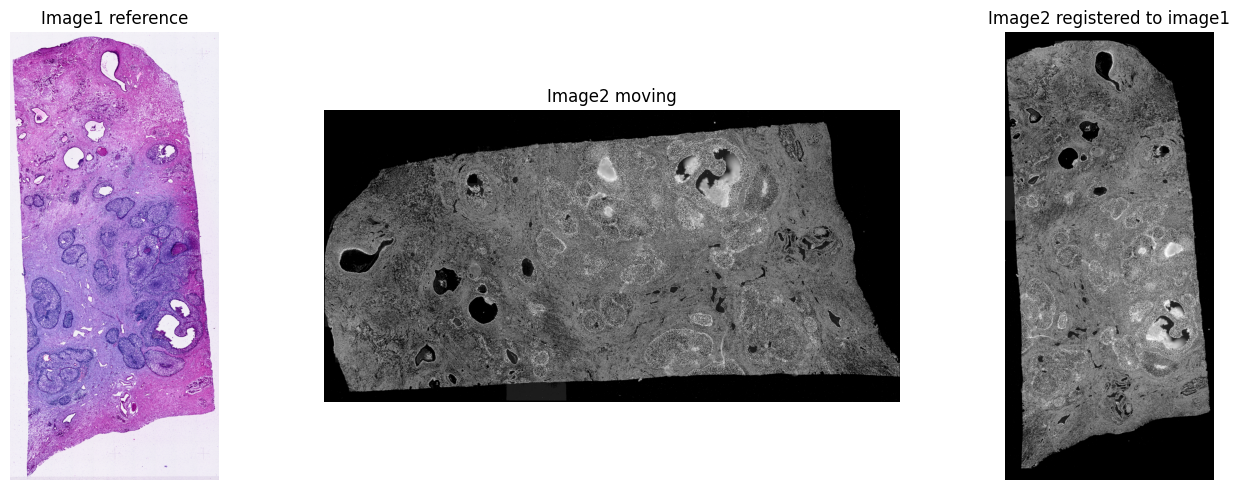

In [5]:
t0 = time.perf_counter()
registration = register(
    image1, image2,
    channels="auto",
    deformable=False,
    sobol_samples=256,
    exploration_rounds=2,
    affine_iterations=(75, 55, 35),
    progress=None,
)
print(f"Global affine registration took {time.perf_counter()-t0:.1f} s")
print("Image1 → Image2 matrix:\n", registration["affine"]["matrix_he_to_af"])
print("Affine NCC:", registration["affine"]["final_ncc"])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, img, title in zip(axes,
                          [image1, image2, registration["affine_registered"]],
                          ["Image1 reference", "Image2 moving", "Image2 registered to image1"]):
    from morphalign import preview_rgb
    ax.imshow(preview_rgb(img))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Two-way point search

The point entered below is always in the **original source image coordinates**. Switching direction swaps which image is the source. Context and radius are measured in *destination-image* pixels.

The figure shows: (1) the source image patch at the input point; (2) an original destination-image patch at the global affine prediction; (3) an original destination-image patch at the refined point; and (4) that refined destination tissue resampled into the source-image coordinate grid using the affine transform plus local correction. Panels 2–3 share the destination pixel scale; panels 1 and 4 share the source pixel scale. NCC is reported numerically.

In [7]:
matcher = MicroMorphAlign(image1, image2, registration=registration)

way = widgets.Dropdown(
    options=[("image1 → image2", "1to2"), ("image2 → image1", "2to1")],
    description="Direction", style={"description_width": "110px"})
xx = widgets.BoundedFloatText(value=float(image1.shape[1] // 2), min=0,
                              max=image1.shape[1]-1, description="x")
yy = widgets.BoundedFloatText(value=float(image1.shape[0] // 2), min=0,
                              max=image1.shape[0]-1, description="y")
context = widgets.IntSlider(value=81, min=21, max=501, step=2,
                            description="Context (px)", continuous_update=False,
                            style={"description_width": "110px"})
search = widgets.IntSlider(value=20, min=2, max=300,
                           description="Radius (px)", continuous_update=False,
                           style={"description_width": "110px"})
cycle = widgets.Checkbox(value=True, description="Bidirectional cycle check")
run_btn = widgets.Button(description="Refine selected point", button_style="success", icon="crosshairs")
point_out = widgets.Output()
last_result = {}

def on_direction(change):
    im = image1 if change["new"] == "1to2" else image2
    xx.max, yy.max = im.shape[1]-1, im.shape[0]-1
    xx.value, yy.value = im.shape[1]//2, im.shape[0]//2

way.observe(on_direction, names="value")

def on_refine(_):
    run_btn.disabled = True
    with point_out:
        clear_output(wait=True)
        try:
            r = matcher.map_point((xx.value, yy.value), direction=way.value,
                                  context_window=context.value,
                                  search_radius=search.value,
                                  check_cycle=cycle.value)
            last_result.clear()
            last_result.update(r)
            fig = plot_match(matcher, r)
            display(fig)
            plt.close(fig)
            print("Original source xy:", tuple(np.round(r["source_point"], 2)))
            print("Global predicted xy:", tuple(np.round(r["predicted"], 2)))
            print("Locally refined xy:", tuple(np.round(r["refined"], 2)))
            print("Correction (dx,dy):", tuple(np.round(r["correction"], 2)))
            print("NCC:", round(r["score"], 4), "  Peak margin:", round(r["peak_margin"], 4))
            print("Valid patch coverage:", f'{r["coverage"]:.1%}')
            if "cycle_error_px" in r:
                print("Cycle consistency error:", round(r["cycle_error_px"], 3), "source pixels")
            print("Note: an NCC maximum is not a validated biological identity.")
        except Exception as exc:
            print("Point refinement unavailable:", type(exc).__name__, str(exc))
            print("Try a point further inside tissue or a smaller context window.")
        finally:
            run_btn.disabled = False

run_btn.on_click(on_refine)
display(widgets.VBox([way, widgets.HBox([xx, yy]), context, search, cycle, run_btn]), point_out)

Output()

## Batch refinement

Once registered, the same `matcher` caches structural features and warps. This is substantially cheaper than running global registration separately for each landmark. Make sure every point has sufficient visible tissue within the selected context window.

In [ ]:
points_image1 = [(image1.shape[1] * a, image1.shape[0] * b)
                 for a, b in [(0.40, 0.40), (0.50, 0.50), (0.60, 0.60)]]
for point in points_image1:
    try:
        out = matcher.map_point(point, direction="1to2", context_window=61, search_radius=20)
        print("image1", tuple(np.round(point, 1)), "→ image2", tuple(np.round(out["refined"], 1)),
              "NCC", round(out["score"], 3))
    except ValueError as error:
        print("Skipped", point, "because", error)